<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Hockey League Data](https://github.com/Query-farm/vgi-nhl)

NHL standings, scores, play-by-play, and player statistics as SQL tables.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nhl/blob/main/notebooks/04_a_roster_does_not_scope_season_totals.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nhl/blob/main/notebooks/README.md)


## A roster does not scope a player’s season totals

**Does joining Florida’s roster to season statistics turn every point into a Florida point?** Compare the roster’s skaters at a common season grain, then follow Brad Marchand’s traded season through game logs, career lines and the profile total. Keep scoring rate, physical-play rate and returned leaderboard rank distinct.

**Real public NHL responses, recorded independently on 2026-11-15 UTC.**
The default replays unchanged response bodies through the real released worker.
These are historical observations, not a synthetic scenario or an atomic live
snapshot. The [provenance manifest](recordings/provenance.json) records exact URLs,
request parameters, acquisition times and hashes. All joins and choices remain visible SQL.

### Choose one local rule

`MIN_GAMES` is an integer 1–82, applied locally to the roster comparison. Change 40→70. The selected players can change; their observed rates and Marchand’s fixed season reconciliation cannot.

In [1]:
DATA_MODE = "replay"
MIN_GAMES = 40

In [2]:
import importlib.metadata

try:
    _shared_version = importlib.metadata.version("vgi-example-notebooks")
except importlib.metadata.PackageNotFoundError:
    _shared_version = None
if _shared_version != "0.3.49":
    %pip -q install "vgi-example-notebooks @ git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.49"
from vgi_notebooks import check_runtime
from vgi_notebooks.bootstrap import prepare

check_runtime()
_companion_directory = prepare("nhl")

In [3]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme
from nhl_examples import NHLExample

if type(MIN_GAMES) is not int or not 1 <= MIN_GAMES <= 82:
    raise ValueError("MIN_GAMES must be an integer from 1 through 82")
source = NHLExample(DATA_MODE, "players")
theme()
session = connect(globals())
SOURCE = (
    "Recorded public NHL responses · captured 2026-11-15 UTC"
    if DATA_MODE == "replay"
    else "Live public NHL responses · independent endpoint reads"
) + " · worker v0.2.0"

### Attach the released worker

The public tag owns dependencies in an isolated Python 3.13 worker environment.
Shared base tooling leaves the kernel intact and starts UTC with an empty temporary
SQL-secret store and persistence disabled. The replay helper redirects all NHL roots
to loopback, verifies response hashes and rejects requests outside this scenario.
Live mode clears inherited URL overrides and never falls back to replay.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nhl' (TYPE vgi, LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-nhl@v0.2.0 vgi-nhl');

,Success


### Join at player, season and game-type grain

`roster` identifies players listed for Florida's 2024–25 season. The league-wide
`skater_stats` report combines every team a player represented; `skater_realtime_stats`
provides hits and other physical-play measures at the same grain. `skater_leaders`
is a bounded top-100 points list. Keep its returned rank, but leave an absent rank
NULL rather than assigning zero or pretending our local filter reproduces that list.
All three season sources use regular-season game type 2.

In [5]:
%%sql
CREATE TABLE roster_rows AS SELECT * FROM nhl.main.roster('FLA',season:=20242025);
CREATE TABLE scoring AS SELECT * FROM nhl.main.skater_stats(season:=20242025);
CREATE TABLE physical AS SELECT * FROM nhl.main.skater_realtime_stats(season:=20242025);
CREATE TABLE leaders AS SELECT * FROM nhl.main.skater_leaders(season:=20242025,category:='points',per_category:=100);
CREATE TABLE roster_metrics AS
SELECT r.player_id,r.player_name,r.position_code,r.team_abbrev AS roster_team,
 s.team_abbrevs AS season_teams,s.season,s.game_type,s.games_played,s.goals,s.assists,s.points,
 p.hits,p.games_played AS physical_games,s.points::DOUBLE/nullif(s.games_played,0) AS points_per_game,
 p.hits::DOUBLE/nullif(p.games_played,0) AS hits_per_game,l.rank AS returned_points_rank,l.value AS leaderboard_points
FROM roster_rows r JOIN scoring s ON r.player_id=s.player_id AND r.season=s.season
JOIN physical p ON s.player_id=p.player_id AND s.season=p.season AND s.game_type=p.game_type
LEFT JOIN leaders l ON s.player_id=l.player_id AND s.season=l.season AND s.game_type=l.game_type AND l.category='points'
WHERE r.position_group<>'goalies';

,Count


In [6]:
%%sql roster_frame <<
SELECT *,games_played>={{MIN_GAMES}} AS selected FROM roster_metrics ORDER BY points DESC,player_id;

,player_id,player_name,position_code,roster_team,season_teams,season,game_type,games_played,goals,assists,points,hits,physical_games,points_per_game,hits_per_game,returned_points_rank,leaderboard_points,selected
0,8477933,Sam Reinhart,C,FLA,FLA,20242025,2,79,39,42,81,103,79,1.025316,1.303797,24,81.0,True
1,8477493,Aleksander Barkov,C,FLA,FLA,20242025,2,67,20,51,71,87,67,1.059701,1.298507,42,71.0,True
2,8479314,Matthew Tkachuk,L,FLA,FLA,20242025,2,52,22,35,57,84,52,1.096154,1.615385,96,57.0,True
3,8477409,Carter Verhaeghe,C,FLA,FLA,20242025,2,81,20,33,53,95,81,0.654321,1.172840,<NA>,NaN,True
4,8473419,Brad Marchand,C,FLA,"BOS,FLA",20242025,2,71,23,28,51,81,71,0.718310,1.140845,<NA>,NaN,True
5,8477935,Sam Bennett,C,FLA,FLA,20242025,2,76,25,26,51,145,76,0.671053,1.907895,<NA>,NaN,True
6,8482113,Anton Lundell,C,FLA,FLA,20242025,2,79,17,28,45,110,79,0.569620,1.392405,<NA>,NaN,True
7,8477495,Seth Jones,D,FLA,"CHI,FLA",20242025,2,63,9,27,36,96,63,0.571429,1.523810,<NA>,NaN,True
8,8477932,Aaron Ekblad,D,FLA,FLA,20242025,2,56,3,30,33,90,56,0.589286,1.607143,<NA>,NaN,True
9,8478542,Evan Rodrigues,C,FLA,FLA,20242025,2,82,15,17,32,128,82,0.390244,1.560976,<NA>,NaN,True


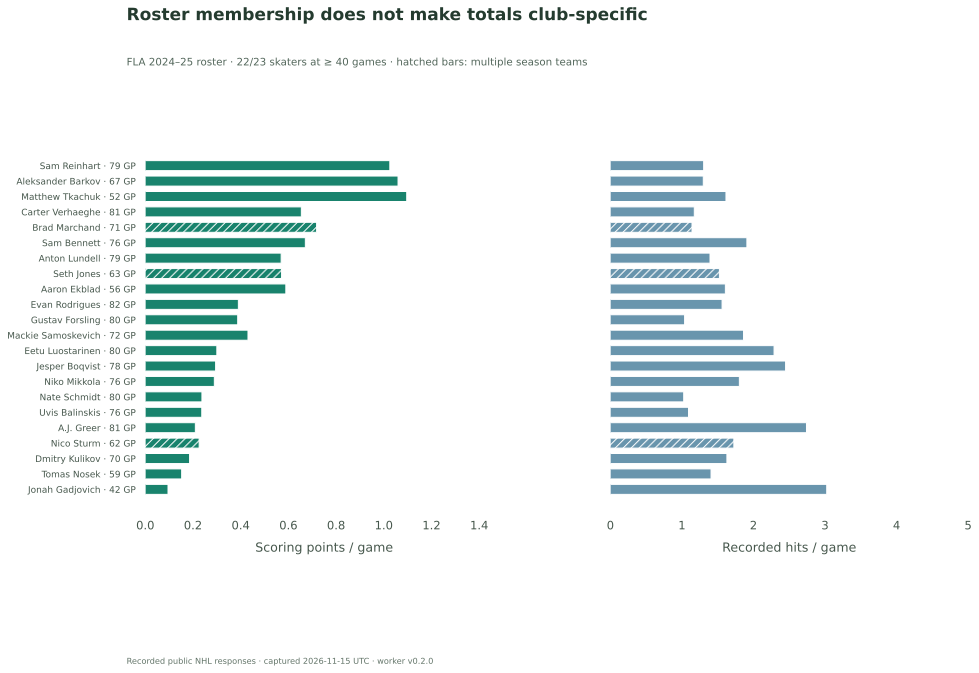

The roster joins to **23 skaters**. **3** have multiple team codes in the season summary, so their totals cannot be attributed wholly to Florida. Only **3** appear in the returned top-100 list. Scoring and hits use separate axes and are not added into a single performance score.

In [7]:
display(roster_frame)
selected = roster_frame[roster_frame.selected].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 10.0), sharey=True)
y = np.arange(len(selected))
for ax, key, label, limit, color in zip(
    axes,
    ["points_per_game", "hits_per_game"],
    ["Scoring points / game", "Recorded hits / game"],
    [1.5, 5.0],
    ["#19836D", "#6995AD"],
    strict=True,
):
    bars = ax.barh(y, selected[key], height=0.65, color=color)
    for bar, teams in zip(bars, selected.season_teams, strict=True):
        if "," in teams:
            bar.set_hatch("///")
    ax.set_xlim(0, limit)
    ax.set_xlabel(label)
axes[0].set_yticks(y, [f"{r.player_name} · {r.games_played} GP" for r in selected.itertuples()], fontsize=9)
axes[0].invert_yaxis()
finish(
    fig,
    "Roster membership does not make totals club-specific",
    f"FLA 2024–25 roster · {len(selected)}/{len(roster_frame)} skaters at ≥ {MIN_GAMES} games · hatched bars: multiple season teams",
    SOURCE,
    name=f"roster-rates-{MIN_GAMES}",
)
prose(
    f"The roster joins to **{len(roster_frame)} skaters**. **{int(roster_frame.season_teams.str.contains(',').sum())}** "
    "have multiple team codes in the season summary, so their totals cannot be attributed wholly to Florida. "
    f"Only **{int(roster_frame.returned_points_rank.notna().sum())}** appear in the returned top-100 list. "
    "Scoring and hits use separate axes and are not added into a single performance score."
)

### Separate current profile, career lines and a single-season log

The selected roster identifies **Brad Marchand, 8473419**. `player` returns his
profile and cumulative NHL regular-season totals at acquisition time; its current
team is not a historical game label. `player_career` also contains other leagues
and playoff lines. Filter both **league='NHL'** and **game type=2** before summing,
then isolate 20242025. `player_game_log` gives the individual regular-season games
and their actual team codes. These returned rows let us distinguish a whole career,
a traded season and a Florida stint without treating them as interchangeable totals.

In [8]:
%%sql
CREATE TABLE profile AS SELECT * FROM nhl.main.player(8473419);
CREATE TABLE career_rows AS SELECT * FROM nhl.main.player_career(8473419);
CREATE TABLE game_rows AS SELECT * FROM nhl.main.player_game_log(8473419,season:=20242025);
CREATE TABLE nhl_regular AS SELECT * FROM career_rows WHERE league_abbrev='NHL' AND game_type=2;
CREATE TABLE season_lines AS SELECT * FROM nhl_regular WHERE season=20242025;
CREATE TABLE stint_audit AS
WITH logs AS(SELECT team_abbrev,count(*) AS log_games,sum(goals) AS log_goals,
 sum(assists) AS log_assists,sum(points) AS log_points FROM game_rows GROUP BY team_abbrev),
 lines AS(SELECT team_name,games_played,goals,assists,points,
 CASE team_name WHEN 'Boston Bruins' THEN 'BOS' WHEN 'Florida Panthers' THEN 'FLA' END AS team_abbrev
 FROM season_lines)
SELECT * FROM logs FULL OUTER JOIN lines USING(team_abbrev);

,Count


The two returned career names are mapped explicitly to BOS and FLA for this
fixed example. The complete mapping is visible, and the full outer join retains
an unmatched line if a name changes. This is not a general fuzzy-name resolver.

In [9]:
%%sql totals <<
SELECT p.player_id,p.player_name,p.current_team_abbrev,p.career_games_played,p.career_points,
 (SELECT sum(games_played) FROM nhl_regular) AS career_line_games,
 (SELECT sum(points) FROM nhl_regular) AS career_line_points,
 (SELECT games_played FROM scoring WHERE player_id=p.player_id) AS season_games,
 (SELECT points FROM scoring WHERE player_id=p.player_id) AS season_points,
 (SELECT count(*) FROM game_rows WHERE team_abbrev='FLA') AS florida_games,
 (SELECT sum(points) FROM game_rows WHERE team_abbrev='FLA') AS florida_points FROM profile p;

In [10]:
display(totals)
row = totals.iloc[0]
prose(
    f"The profile has **{int(row.career_points):,} career points** at acquisition time. "
    f"The chosen 2024–25 season has **{int(row.season_points)}**, of which the game log attributes "
    f"**{int(row.florida_points)}** to Florida. Those are three different time/team scopes. "
    "The current-team field is displayed for context, not used to reassign earlier points."
)

,player_id,player_name,current_team_abbrev,career_games_played,career_points,career_line_games,career_line_points,season_games,season_points,florida_games,florida_points
0,8473419,Brad Marchand,FLA,1154,1035,1154.0,1035.0,71,51,10,4.0


The profile has **1,035 career points** at acquisition time. The chosen 2024–25 season has **51**, of which the game log attributes **4** to Florida. Those are three different time/team scopes. The current-team field is displayed for context, not used to reassign earlier points.

In [11]:
%%sql stints <<
SELECT * FROM stint_audit ORDER BY team_abbrev;

,team_abbrev,log_games,log_goals,log_assists,log_points,team_name,games_played,goals,assists,points
0,BOS,61,21.0,26.0,47.0,Boston Bruins,61,21,26,47
1,FLA,10,2.0,2.0,4.0,Florida Panthers,10,2,2,4


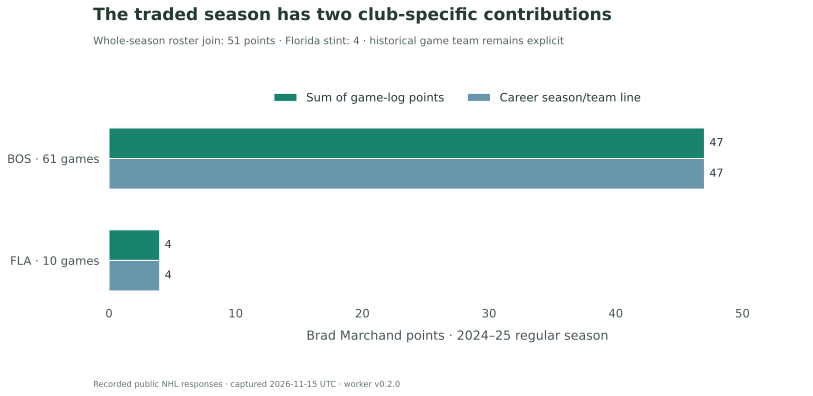

The **2** returned stints reconcile independently for games, goals, assists and points. The cohort's minimum-games rule changes neither this decomposition nor the profile's career total.

In [12]:
display(stints)
fig, ax = plt.subplots(figsize=(11, 5.8))
y = np.arange(len(stints))
width = 0.3
for offset, key, label, color in [
    (-0.5, "log_points", "Sum of game-log points", "#19836D"),
    (0.5, "points", "Career season/team line", "#6995AD"),
]:
    bars = ax.barh(y + offset * width, stints[key], height=width, color=color, label=label)
    ax.bar_label(bars, padding=5, fmt="%g", fontsize=11)
ax.set_yticks(y, [f"{r.team_abbrev} · {r.log_games} games" for r in stints.itertuples()])
ax.invert_yaxis()
ax.set_xlim(0, 55)
ax.set_xlabel("Brad Marchand points · 2024–25 regular season")
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.53, 0.79), ncol=2)
finish(
    fig,
    "The traded season has two club-specific contributions",
    "Whole-season roster join: 51 points · Florida stint: 4 · historical game team remains explicit",
    SOURCE,
    name="marchand-stints",
)
prose(
    f"The **{len(stints)}** returned stints reconcile independently for games, goals, assists and points. "
    "The cohort's minimum-games rule changes neither this decomposition nor the profile's career total."
)

In [13]:
%%sql checks <<
SELECT 'unique roster player keys' check_name,count(*)=count(DISTINCT player_id) passed FROM roster_rows
UNION ALL SELECT 'all roster skaters retained',count(*)=(SELECT count(*) FROM roster_rows WHERE position_group<>'goalies') FROM roster_metrics
UNION ALL SELECT 'unique joined skaters',count(*)=count(DISTINCT player_id) FROM roster_metrics
UNION ALL SELECT 'same season and game type',bool_and(season=20242025 AND game_type=2) FROM roster_metrics
UNION ALL SELECT 'games agree across season reports',bool_and(games_played=physical_games) FROM roster_metrics
UNION ALL SELECT 'scoring point identity',bool_and(points=goals+assists) FROM roster_metrics
UNION ALL SELECT 'leaderboard values agree when present',bool_and(points=leaderboard_points) FROM roster_metrics WHERE returned_points_rank IS NOT NULL
UNION ALL SELECT 'selected player in roster',count(*)=1 FROM roster_metrics WHERE player_id=8473419
UNION ALL SELECT 'profile career reconciles',career_points=(SELECT sum(points) FROM nhl_regular) AND career_games_played=(SELECT sum(games_played) FROM nhl_regular) FROM profile
UNION ALL SELECT 'unique game log keys',count(*)=count(DISTINCT game_id) FROM game_rows
UNION ALL SELECT 'both stint sources present',count(*)=2 AND count(team_name)=2 AND count(log_games)=2 FROM stint_audit
UNION ALL SELECT 'stint quantities reconcile',bool_and(log_games=games_played AND log_goals=goals AND log_assists=assists AND log_points=points) FROM stint_audit
UNION ALL SELECT 'season totals reconcile',sum(log_points)=(SELECT points FROM scoring WHERE player_id=8473419) AND sum(log_games)=(SELECT games_played FROM scoring WHERE player_id=8473419) FROM stint_audit;

In [14]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
prose(f"**All {len(checks)} SQL checks passed.** " + source.audit())
Path("artifacts").mkdir(exist_ok=True)
Path("artifacts/analysis-04.json").write_text(
    json.dumps(
        {
            "parameters": {"MIN_GAMES": MIN_GAMES, "DATA_MODE": DATA_MODE},
            "roster_frame": roster_frame.to_dict("records"),
            "totals": totals.to_dict("records"),
            "stints": stints.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": source.requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)

,check_name,passed
0,unique roster player keys,True
1,all roster skaters retained,True
2,unique joined skaters,True
3,same season and game type,True
4,games agree across season reports,True
5,scoring point identity,True
6,leaderboard values agree when present,True
7,selected player in roster,True
8,profile career reconciles,True
9,unique game log keys,True


**All 13 SQL checks passed.** Exactly 6 recorded HTTP responses requested once each; no unexpected requests.

14285

### Change one thing

Change **MIN_GAMES 40→70**. The local roster comparison contracts from 22 to 15 skaters in this recording. Retained player rates and returned leaderboard ranks stay fixed; the Marchand decomposition and its second chart must remain identical.

In [15]:
assert not con.execute("SELECT * FROM duckdb_secrets()").fetchall()
session.close()
source.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nhl](https://github.com/Query-farm/vgi-nhl)